Lowest Vibrational Energy (E_0) = -1.362e-07 MeV


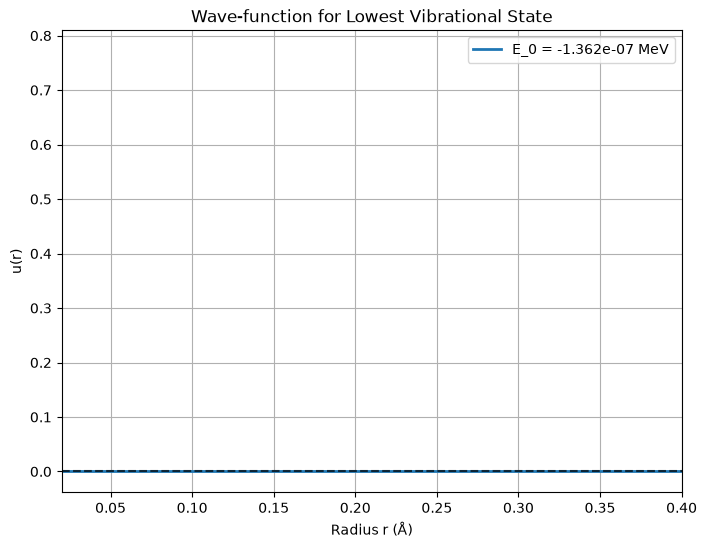

In [40]:
import matplotlib.pyplot as plt
import numpy as np

# Physical constants
hbar_c = 1973.0 * 10**(-6)                             # ħc in MeV·Å 
m = 940.0                                      # Reduced mass in MeV/c^2 (940 x 10^6 eV/c^2)
hbar2_over_2m = (hbar_c**2) / (2.0 * m)


r_not = 0.131349  # in Å
alpha = 1.44  # in Å^-1
D = 0.755501 * 10**(-6)  # in MeV (0.755501 eV)

# Grid setup
N = 2000
r_min = 0.01  # in Å
r_max = 3.0  # in Å
r = np.linspace(r_min, r_max, N)
h = r[1] - r[0]  # Step size

# Finite difference Kinetic Energy operator matrix
main_diag = 2.0 * np.ones(N)
off_diag = -1.0 * np.ones(N - 1)
K = (hbar2_over_2m / (h**2)) * (
    np.diag(main_diag) + np.diag(off_diag, 1) + np.diag(off_diag, -1)
)

# Potential energy from image: V(r) = D * (exp(-2*alpha*r') - exp(-alpha*r'))
r_dash = (r - r_not) / r
V = D * (np.exp(-2 * alpha * r_dash) - np.exp(-alpha * r_dash))

# Hamiltonian matrix
H = K + np.diag(V)


energies, wavefunctions = np.linalg.eigh(H)
lowest_Vibrational_energy = energies[0]


print(f"Lowest Vibrational Energy (E_0) = {lowest_Vibrational_energy:.3e} MeV")


plt.figure(figsize=(8, 6))
u = wavefunctions[:, 0] / np.sqrt(h)
if u[1] < 0:
  u = -u

plt.plot(r, u, label=f"E_0 = {lowest_Vibrational_energy:.3e} MeV", linewidth=2)
plt.axhline(0, color="black", linestyle="--", alpha=0.7)
plt.title("Wave-function for Lowest Vibrational State")
plt.xlabel("Radius r (Å)")
plt.ylabel("u(r)")
plt.legend()
plt.xlim(0.02, 0.4)
plt.grid(True)
plt.show()